# SQG turbulence at $N = 128$, nonlinear observations

The same two-surface SQG model as the linear experiment — $20\,000\,$km doubly periodic
square, $128^2$ points per surface, $d = 32768$, $L_R = 1000\,$km, $N_e = 16$ — with a
saturating observation operator.

| | |
|---|---|
| analyses | 24-hourly, 150 cycles, cycles 75-149 scored |
| observations | $25\,\%$ of the $2N^2$ points, both surfaces, network redrawn each cycle |
| operator | $h(\theta) = s\arctan(\theta/s)$, $s = 2.3\,$K, $\sigma_{\rm obs} = 0.1559\,$K |
| initial ensemble | climatological, 16 states from a long free run |
| seeds | 10 evaluation (0-9), 3 tuning (100-102), disjoint |

$\sigma_{\rm obs}$ is information-matched: it is chosen so that the median equivalent
state-space error $\sigma_{\rm obs}/|h'(\theta)|$ along the truth trajectory matches the
$1\,$K of the linear experiment.

Each method was given a $4 \times 6$ grid over a localization length and a spread-control
parameter, tuned on the three seeds that are not evaluated, and a setting was eligible only
if it was usable on every tuning seed. That grid was measured under the earlier two-sided
prior-scaling rule; the settings it selected — $L = 1000\,$km with $\kappa = 0.025$ for
CI-EnSF, $L = 500\,$km with RTPS $= 0.3$ for the LETKF — are carried over unchanged and are
not re-selected. The grid itself is not reproduced here. $N_t$ is not in either grid: it is
measured per localization radius by a discretization pre-flight.

**Produces** Table 6, Figure 6 and Figure 7 of the manuscript. The selected settings are
hard-coded in section 1. `RUN_SIMULATION = False` rebuilds them from the stored results in
`sqg/`; `True` re-runs the filters, which needs a GPU and the nature runs.

## 1. Configuration and the selected settings

In [1]:
import os, sys, json, numpy as np
import matplotlib
import matplotlib.pyplot as plt

def _find_sqg():
    """Walk up from the working directory until a sqg/ directory appears, so the same file
    works in the development tree and in the reproducibility repository."""
    q = os.path.abspath(os.curdir)
    for _ in range(4):
        cand = os.path.join(q, "sqg")
        if os.path.isdir(cand):
            return cand
        q = os.path.dirname(q)
    raise SystemExit("could not locate the sqg/ directory; set CIENSF_SQG to point at it")

SQG = os.environ.get("CIENSF_SQG") or _find_sqg()
sys.path.insert(0, SQG)

RUN_SIMULATION = False     # True -> re-run the filters (GPU, and needs sqg/nature/)

# ---------------- the experiment, exactly as the filters were run
N, D, KENS   = 128, 2*128*128, 16
L_DOM, LR, H = 20000e3, 1000e3, 10e3
DT_OBS_H     = 24.0
N_CYCLE, SCORE_FROM = 150, 75
OBS_FRAC     = 0.25
EVAL_SEEDS   = tuple(range(10))
OPERATOR     = dict(kind="arctan_k", arctan_s=2.3, sigma_obs=0.1559)  # h = s*arctan(x/s)

# ---------------- selected hyperparameters, all literals.  The sensitivity grids that
# selected them were measured under the earlier controller and are not reproduced here.
TUNED = {"CI-EnSF": dict(lloc_km=1000, kappa=0.025, n_t=1600),
         "LETKF":   dict(lloc_km=500,  rtps=0.3)}
# gamma controller (simplified rule):  gamma <- clip(gamma * rho_s**P_GAIN, LO, HI)
GAMMA0, GAMMA_LO, GAMMA_HI = 0.1, 0.05, 0.5
P_GAIN, W_SMOOTH           = 0.5, 0.3

EVAL_JSON = os.path.join(SQG, "arctan_k_eval_simple.json")
SPEC_JSON = os.path.join(SQG, "ak_spec_diag_simple.json")
FLD_NPZ   = os.path.join(SQG, "ak_figure_fields.npz")

# The snapshot figure draws one level at the final cycle, so only that is kept, with the
# colour limits it uses.  Those are taken over every cycle, as the full run would give them.
FIG_LEV = 1
def figure_fields(f):
    T = f["truth"][:, FIG_LEV]
    E = [f[m][:, FIG_LEV] - T for m in ("CI-EnSF", "LETKF")]
    out = {m: f[m][-1, FIG_LEV] for m in ("truth", "CI-EnSF", "LETKF")}
    out.update({m + s: f[m + s] for m in ("CI-EnSF", "LETKF")
                for s in ("_rmse_obs", "_rmse_unobs")})
    out["vmax"] = np.abs(T).max()
    out["dmax"] = np.percentile(np.abs(np.concatenate(E)), 99.5)
    return out

## 2. Re-running the filters

`RUN_SIMULATION = False` skips this section and the table and figures below are rebuilt from
the stored results. Setting it to `True` re-runs both filters over the ten evaluation seeds
and rewrites those files. That needs a GPU and the nature runs (see **Nature runs** in the
README; point `SQG_NATURE_DIR` at them), and takes about 24 minutes per seed for CI-EnSF at
$N_t = 1600$ over 150 cycles.

One pass per seed produces everything: the scored metrics of Table 6 from the per-cycle
history, the spectral sums of Figure 7 from an ensemble hook, and the seed-0 analysis fields
of Figure 6 from the field sink. The spectra are accumulated as exact sums, so sharding the
seeds across processes does not change them.

In [2]:
if RUN_SIMULATION:
    import time
    os.environ.update(SQG_N="128", SQG_GPU="1", SQG_OBS="arctan_k",
                      SQG_ARCTAN_S=str(OPERATOR["arctan_s"]),
                      SQG_SIGMA_OBS=str(OPERATOR["sigma_obs"]),
                      SQG_NCYC="160", SQG_CLIM="24",
                      SQG_NT=str(TUNED["CI-EnSF"]["n_t"]), SQG_ADAPT_NT="0",
                      SQG_GAMMA_RULE="simple")
    import sqg_cvt as S, gpu, bfree

    assert S.GAMMA_RULE == "simple", S.GAMMA_RULE
    N, L = S.N, S.L_DOM
    S.DT_OBS = DT_OBS_H*3600.0; S.NSTEP_OBS = int(round(S.DT_OBS/S.DT))
    S.OBS_LEVEL, S.OBS_FRAC, S.INIT = "both", OBS_FRAC, "clim"
    S.GAMMA0, S.GAMMA_LO, S.GAMMA_HI = GAMMA0, GAMMA_LO, GAMMA_HI

    # --- spectral machinery: binned kinetic-energy density of the two-surface inversion
    _M   = S.make_model(np.zeros((2, N, N)))
    KSQ  = np.asarray(_M.ksqlsq, np.float64)
    HOM, TAN, SIN = (np.asarray(getattr(_M, a), np.float64)
                     for a in ("Hovermu", "tanhmu", "sinhmu"))
    _W   = np.full((N, N//2+1), 2.0); _W[:, 0] = 1.0; _W[:, -1] = 1.0
    _kx  = np.arange(N//2+1); _ky = np.fft.fftfreq(N)*N
    _KI  = np.sqrt(_kx[None, :]**2 + _ky[:, None]**2)
    _EDG = np.arange(0.5, N//2+1.0); KCEN = 0.5*(_EDG[1:]+_EDG[:-1])
    _BIN = np.digitize(_KI.ravel(), _EDG); _NB = len(_EDG)-1

    def ke_spectrum(theta):
        pv = np.asarray(theta, np.float64)/S.SCALE
        F  = np.fft.rfft2(pv, axes=(-2, -1))/(N*N)
        p0 = HOM*((F[:, 1]/SIN) - (F[:, 0]/TAN))
        p1 = HOM*((F[:, 1]/TAN) - (F[:, 0]/SIN))
        ke = (0.5*KSQ*_W*(np.abs(p0)**2 + np.abs(p1)**2)).mean(0).ravel()
        return np.bincount(_BIN, weights=ke, minlength=_NB+1)[1:_NB+1]

    RUNS = {"CI-EnSF": dict(mode="adapt", kappa=TUNED["CI-EnSF"]["kappa"],
                            lloc=TUNED["CI-EnSF"]["lloc_km"]*1e3),
            "LETKF":   dict(mode="letkf", kappa=0.0,
                            lloc=TUNED["LETKF"]["lloc_km"]*1e3,
                            rtps=TUNED["LETKF"]["rtps"])}
    acc  = {m: dict(err=np.zeros(_NB), pert=np.zeros(_NB), n=0) for m in RUNS}
    tru  = dict(s=np.zeros(_NB), n=0)
    per  = {m: [] for m in RUNS}
    flds = {}
    NAT  = os.environ.get("SQG_NATURE_DIR", os.path.join(SQG, "nature"))

    for seed in EVAL_SEEDS:
        q = os.path.join(NAT, "ak24_N128_seed%d.npz" % seed)
        if not os.path.exists(q): q = os.path.join(NAT, "nat24_seed%d.npz" % seed)
        z = np.load(q); T, C = z["T"], z["C"]
        S.nature_run = lambda _s, _T=T, _C=C: (_T, _C)
        Tf = np.asarray(T, np.float64).reshape(len(T), 2, N, N)
        FAIL = 0.5*float(Tf.std())
        tru["s"] += ke_spectrum(Tf[SCORE_FROM:N_CYCLE])*(N_CYCLE-SCORE_FROM)
        tru["n"] += N_CYCLE-SCORE_FROM
        if seed == 0: flds["truth"] = np.asarray(T[:N_CYCLE], np.float32)

        for name, kw in RUNS.items():
            S.LLOC = kw["lloc"]
            if name == "LETKF": S.RTPS = kw["rtps"]
            else:               S.BF = bfree.BFree(N, L, S.LLOC, alpha=1.0)
            a = acc[name]

            def hook(X, n, _a=a, _Tf=Tf):
                if n < SCORE_FROM: return
                Xn = gpu.asnumpy(X).reshape(KENS, 2, N, N); xb = Xn.mean(0)
                _a["err"]  += ke_spectrum((xb - _Tf[n])[None])
                _a["pert"] += ke_spectrum(Xn - xb)*KENS/(KENS-1.0)
                _a["n"]    += 1
            S.run.ens_hook = hook
            if seed == 0: S.run.field_sink = []

            t0 = time.time()
            h, f = S.run(seed, kw["mode"], kappa=kw["kappa"], nc=N_CYCLE, verbose=False)
            h = np.asarray(h); del S.run.ens_hook

            rec = dict(seed=seed, status="ok" if not f else "fail",
                       fail_cycle=int(f) if f else 0, secs=round(time.time()-t0, 1))
            if not f and len(h) > SCORE_FROM:
                w = h[SCORE_FROM:]
                rec.update(rmse=float(w[:, 0].mean()), sp_rms=float(w[:, 2].mean()),
                           gamma=float(w[:, 3].mean()), sqrt_r_eff=float(w[:, 4].mean()),
                           rmse_obs=float(w[:, 10].mean()),
                           rmse_unobs=float(w[:, 11].mean()))
                if rec["rmse"] > FAIL: rec["status"] = "divergence"
            else:
                rec.update(rmse=None)
            per[name].append(rec)

            if seed == 0:
                flds[name] = np.asarray(S.run.field_sink, np.float32); del S.run.field_sink
                for suf, col in (("_rmse", 0), ("_rmse0", 6), ("_rmse1", 7),
                                 ("_rmse_obs", 10), ("_rmse_unobs", 11)):
                    flds[name + suf] = h[:, col].astype(np.float32)
            print("  seed %d %-9s %s  [%.0f s]"
                  % (seed, name, ("rmse %.4f" % rec["rmse"]) if rec["rmse"] else rec["status"],
                     rec["secs"]), flush=True)

    ev = {}
    for m in RUNS:
        ok = [r for r in per[m] if r["status"] == "ok"]
        if not ok:
            raise RuntimeError(
                "%s lost every seed: %s. Check N_t, the nature runs and the GPU."
                % (m, [(r["seed"], r["status"]) for r in per[m]]))
        r  = np.array([x["rmse"] for x in ok])
        ev[m] = dict(per_seed=per[m], n_seeds=len(per[m]), n_ok=len(ok),
                     rmse_mean=float(r.mean()),
                     rmse_sem=float(r.std(ddof=1)/np.sqrt(len(r))),
                     rmse_min=float(r.min()), rmse_max=float(r.max()),
                     sp_rms=float(np.mean([x["sp_rms"] for x in ok])),
                     rmse_obs=float(np.mean([x["rmse_obs"] for x in ok])),
                     rmse_unobs=float(np.mean([x["rmse_unobs"] for x in ok])),
                     gamma=float(np.mean([x["gamma"] for x in ok])),
                     sqrt_r_eff=float(np.mean([x["sqrt_r_eff"] for x in ok])))
    json.dump({"config": dict(rule="simple", gamma0=GAMMA0, gamma_lo=GAMMA_LO,
                              gamma_hi=GAMMA_HI, nt=TUNED["CI-EnSF"]["n_t"],
                              score_from=SCORE_FROM, n_cycle=N_CYCLE, tuned=TUNED),
               "evaluation": ev}, open(EVAL_JSON, "w"), indent=1)

    spec = {"k": KCEN.tolist(), "n_seeds": len(EVAL_SEEDS), "seeds": list(EVAL_SEEDS),
            "score_from": SCORE_FROM, "n_cycle": N_CYCLE, "kens": KENS,
            "lloc_km": {m: TUNED[m]["lloc_km"] for m in RUNS}, "obs_frac": OBS_FRAC,
            "rule": "simple",
            "truth": {"err": (tru["s"]/tru["n"]).tolist()}}
    for m in RUNS:
        n = acc[m]["n"]
        spec[m] = {"err": (acc[m]["err"]/n).tolist(),
                   "pert": (acc[m]["pert"]/n).tolist(), "n_samples": n}
    json.dump(spec, open(SPEC_JSON, "w"))
    np.savez_compressed(FLD_NPZ, **figure_fields(flds))

EV   = json.load(open(EVAL_JSON))
SPEC = json.load(open(SPEC_JSON))
FLD  = np.load(FLD_NPZ)


## 3. Table 6

Five columns: method, stable realizations, mean RMSE over the stable realizations, the
smallest and largest realization-mean RMSE among them, and spread/RMSE. The finite-ensemble
reference for spread/RMSE is $\sqrt{N_e/(N_e+1)} = 0.970$ at $N_e = 16$.

In [3]:
# Row order follows the manuscript: the method under test first, then the baseline.
ORDER = ["CI-EnSF", "LETKF"]

def latex_table():
    o = [r"\begin{tabular}{lcccc}", r"\toprule",
         r"Method & Stable realizations & RMSE (K) & RMSE range (K) & Spread/RMSE \\",
         r"\midrule"]
    for m in ORDER:
        e = EV["evaluation"][m]
        o.append("%s & %d/%d & %.4f & %.4f--%.4f & %.2f \\\\"
                 % (m, e["n_ok"], e["n_seeds"], e["rmse_mean"],
                    e["rmse_min"], e["rmse_max"], e["sp_rms"]))
    o += [r"\bottomrule", r"\end{tabular}"]
    return "\n".join(o)

print(latex_table())

\begin{tabular}{lcccc}
\toprule
Method & Stable realizations & RMSE (K) & RMSE range (K) & Spread/RMSE \\
\midrule
CI-EnSF & 10/10 & 1.7603 & 1.6547--1.8657 & 0.97 \\
LETKF & 6/10 & 2.2191 & 2.0065--2.3961 & 0.91 \\
\bottomrule
\end{tabular}


## 4. Figure 6

The final analysis cycle of a realization on which both methods remain stable. (a)-(c) the
truth and the two analyses at the upper surface; (e)-(f) the corresponding error fields on a
common colour scale; (d) analysis RMSE per cycle, split into the directly observed and the
unobserved components.

wrote arctan_k_snapshot.pdf / .png  (cycle 150, the final analysis cycle)


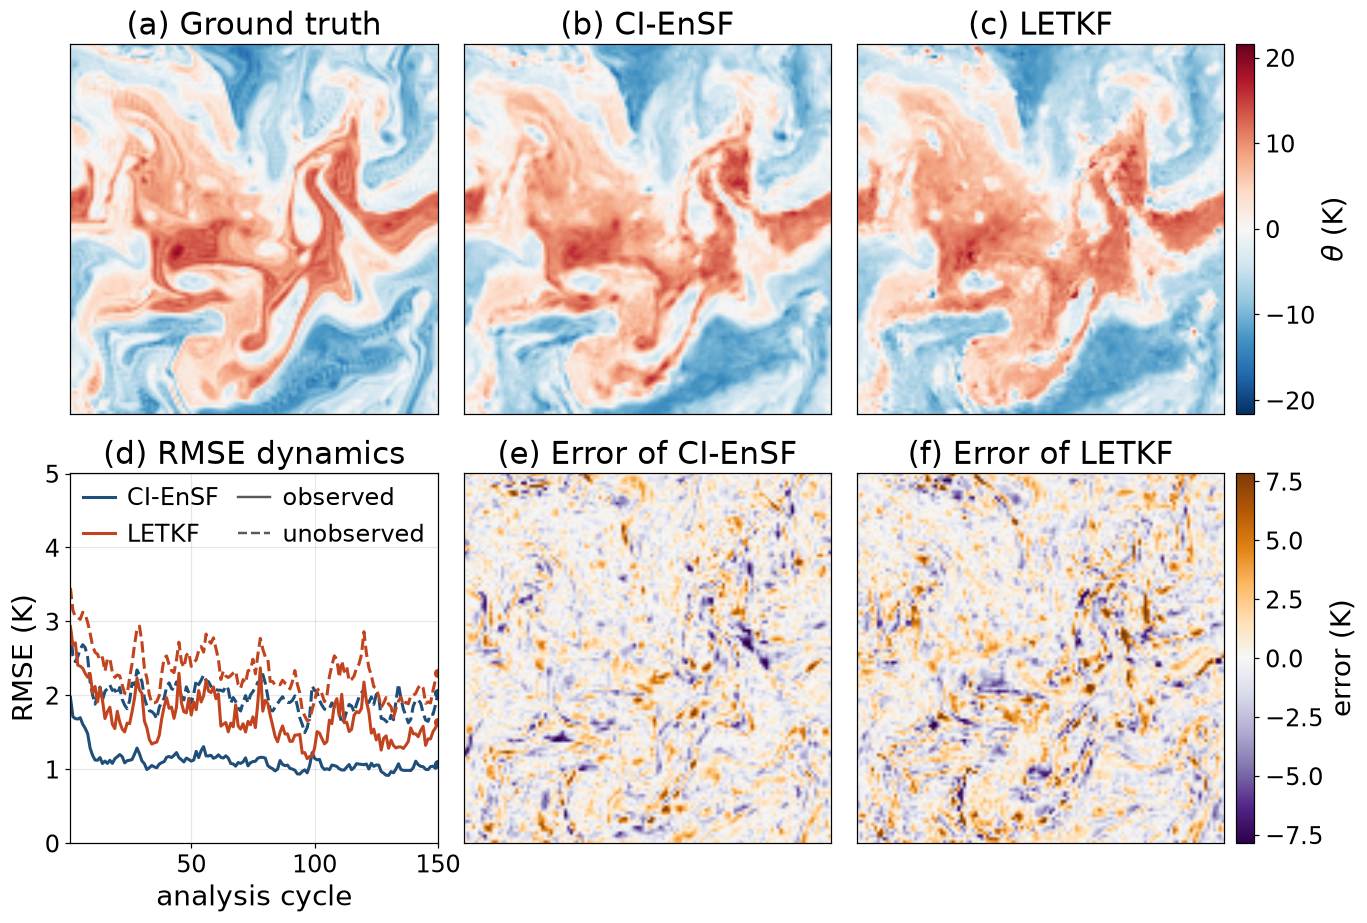

In [4]:
from matplotlib.lines import Line2D

# level FIG_LEV at the final cycle; the colour limits come with it (see figure_fields)
truth, cvtF, letF = FLD["truth"], FLD["CI-EnSF"], FLD["LETKF"]
dC, dL = cvtF - truth, letF - truth
SER   = (FLD["CI-EnSF_rmse_obs"], FLD["CI-EnSF_rmse_unobs"],
         FLD["LETKF_rmse_obs"],    FLD["LETKF_rmse_unobs"])
NF    = len(SER[0])
VMAX, DMAX = float(FLD["vmax"]), float(FLD["dmax"])
EXT   = [0, L_DOM/1e3, 0, L_DOM/1e3]

# one place to set the type sizes, so the figure can be made legible at print size.
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG = 20, 18, 16, 16

def build():
    """The six panels at the final analysis cycle."""
    plt.rcParams.update({"font.size": FS_LABEL, "figure.dpi": 110})
    fig = plt.figure(figsize=(13.0, 8.6))
    # A plain 2x3 grid: every panel, maps and line plot alike, gets the same box.  The
    # colourbars are placed by hand below so the gap to the maps is set, not inherited
    # from a spacer column.
    gs  = fig.add_gridspec(2, 3, hspace=0.16, wspace=0.07)
    A   = [fig.add_subplot(gs[0, i]) for i in range(3)]
    B1  = fig.add_subplot(gs[1, 0])
    B   = [fig.add_subplot(gs[1, i]) for i in (1, 2)]
    ims = []
    for a, f, t in zip(A, (truth, cvtF, letF),
                       ("(a) Ground truth", "(b) CI-EnSF", "(c) LETKF")):
        ims.append(a.imshow(f, origin="lower", extent=EXT, cmap="RdBu_r", aspect="auto",
                            vmin=-VMAX, vmax=VMAX, interpolation="bilinear"))
        a.set_title(t, fontsize=FS_TITLE)
        a.set_xticks([]); a.set_yticks([])   # bare maps: the frame is the only decoration
    for b, d, t in zip(B, (dC, dL), ("(e) Error of CI-EnSF", "(f) Error of LETKF")):
        ims.append(b.imshow(d, origin="lower", extent=EXT, cmap="PuOr_r", aspect="auto",
                            vmin=-DMAX, vmax=DMAX, interpolation="bilinear"))
        b.set_title(t, fontsize=FS_TITLE)
        b.set_xticks([]); b.set_yticks([])

    k = np.arange(1, NF+1)
    style = (("#1f4e79","-"), ("#1f4e79","--"), ("#c1441e","-"), ("#c1441e","--"))
    for y, (c, ls) in zip(SER, style):
        B1.plot(k, y, color=c, ls=ls, lw=2.0); B1.plot([NF], [y[-1]], "o", color=c, ms=5)
    B1.set_xlim(1, NF)
    B1.set_ylim(0.0, 1.45*max(SER[1].max(), SER[3].max()))   # linear, from zero
    B1.set_xlabel("analysis cycle", fontsize=FS_LABEL)
    B1.set_ylabel("RMSE (K)", fontsize=FS_LABEL)
    B1.set_title("(d) RMSE dynamics", fontsize=FS_TITLE)
    B1.grid(alpha=.3); B1.tick_params(labelsize=FS_TICK)
    B1.legend(handles=[Line2D([],[],color="#1f4e79",lw=2.0,label="CI-EnSF"),
                       Line2D([],[],color="#c1441e",lw=2.0,label="LETKF"),
                       Line2D([],[],color="0.35",lw=1.6,ls="-", label="observed"),
                       Line2D([],[],color="0.35",lw=1.6,ls="--",label="unobserved")],
              fontsize=FS_LEG, loc="upper right", frameon=False, ncol=2,
              handlelength=1.3, handletextpad=0.5, columnspacing=0.8,
              borderaxespad=0.15)   # at FS_LEG=16 the legend is 3.30 in and the panel 3.34,
                                    # so it only clears the left spine with the padding cut
    fig.subplots_adjust(left=0.065, right=0.872, top=0.945, bottom=0.100)

    GAP, CW = 0.008, 0.013          # map-to-colourbar gap and bar width, figure fractions
    for src, row, lab in ((ims[0], A[2], r"$\theta$ (K)"), (ims[3], B[1], "error (K)")):
        p  = row.get_position()
        cb = fig.colorbar(src, cax=fig.add_axes([p.x1 + GAP, p.y0, CW, p.height]))
        cb.set_label(lab, fontsize=FS_LABEL); cb.ax.tick_params(labelsize=FS_TICK)

    return fig

fig = build()
fig.savefig("arctan_k_snapshot.pdf")
fig.savefig("arctan_k_snapshot.png", dpi=140)
print("wrote arctan_k_snapshot.pdf / .png  (cycle %d, the final analysis cycle)" % NF)
plt.show()

## 5. Figure 7

The same analyses decomposed by scale. (a) kinetic energy of the analysis-mean error (solid)
and of the analysis perturbations (dashed) for each method, with the nature run's spectrum as
reference; the perturbation spectrum is the unbiased ensemble variance. (b) the fraction of
the LETKF's error energy that CI-EnSF removes, shell by shell. (c) the consistency ratio,
perturbation energy over error energy, whose target is one at every scale.

The spectra are accumulated over the evaluation window of all ten realizations as exact sums
rather than means of means.

wrote sqg_n128_arctan_spectra.pdf / .png   (64 bins, 10 seeds; samples per method: CI-EnSF 750, LETKF 453)


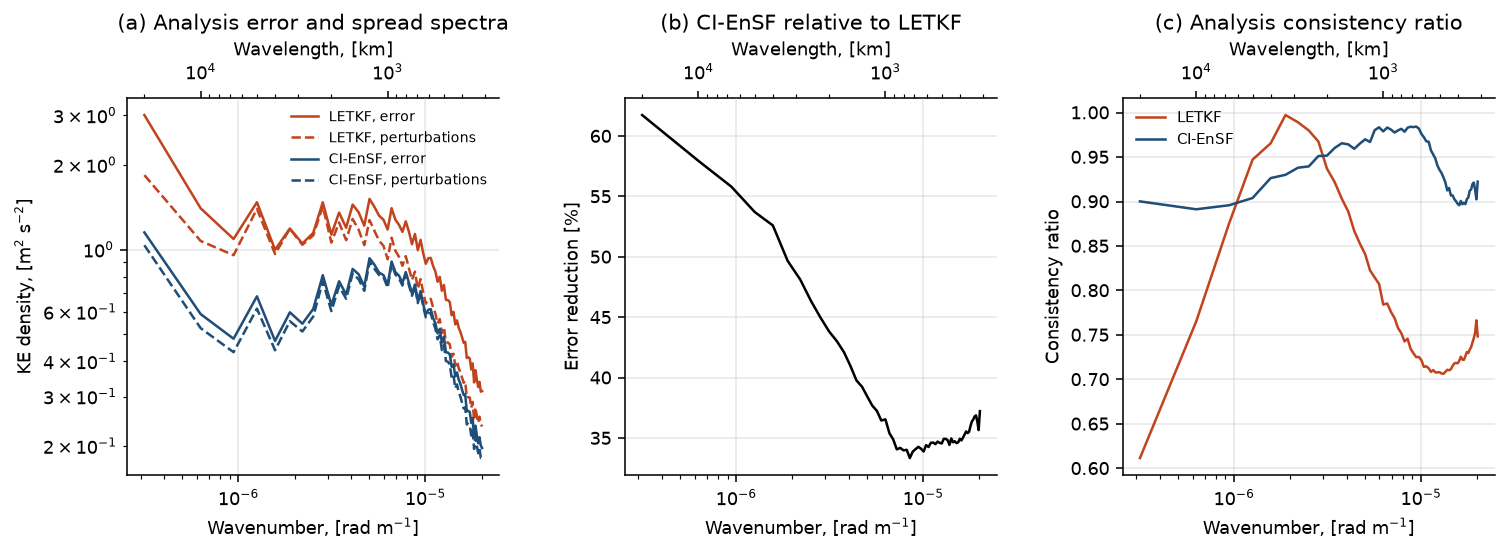

In [5]:
plt.rcParams.update({"font.size":9, "axes.grid":True, "grid.alpha":.3,
                     "legend.frameon":False, "axes.spines.top":False,
                     "axes.spines.right":False, "figure.dpi":140,
                     "savefig.bbox":"tight", "lines.linewidth":1.3})
k_idx = np.array(SPEC["k"])
kph   = 2*np.pi*k_idx/L_DOM                    # physical wavenumber, rad/m
# Per shell of unit NON-dimensional wavenumber, i.e. the binned sum, in m^2 s^-2.  The
# published axis of the figure this follows reads m^3 s^-2, which would be per unit rad/m,
# but dividing by that bin width (2 pi/L = 3.1e-7) multiplies every curve by 3.2e6 and lands
# the error spectra near 1e6, where the published curves sit between 1e-2 and 3e-1 -- the
# range the binned sums occupy.  The plotted values, not the unit string, fix the convention.
COLS  = {"CI-EnSF": "#1f4e79", "LETKF": "#c1441e"}
ERR   = {m: np.array(SPEC[m]["err"])  for m in COLS}
PERT  = {m: np.array(SPEC[m]["pert"]) for m in COLS}

fig, ax = plt.subplots(1, 3, figsize=(12.6, 3.5))
for m in ("LETKF", "CI-EnSF"):
    ax[0].plot(kph, ERR[m],  color=COLS[m], ls="-",  label="%s, error" % m)
    ax[0].plot(kph, PERT[m], color=COLS[m], ls="--", label="%s, perturbations" % m)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Wavenumber, [rad m$^{-1}$]")
ax[0].set_ylabel("KE density, [m$^2$ s$^{-2}$]")
ax[0].set_title("(a) Analysis error and spread spectra")
ax[0].legend(fontsize=7, loc="upper right")

ax[1].plot(kph, 100*(ERR["LETKF"] - ERR["CI-EnSF"])/ERR["LETKF"], color="k")
ax[1].set_xscale("log"); ax[1].set_xlabel("Wavenumber, [rad m$^{-1}$]")
ax[1].set_ylabel("Error reduction [%]")
ax[1].set_title("(b) CI-EnSF relative to LETKF")

for m in ("LETKF", "CI-EnSF"):
    ax[2].plot(kph, PERT[m]/ERR[m], color=COLS[m], label=m)
ax[2].set_xscale("log"); ax[2].set_xlabel("Wavenumber, [rad m$^{-1}$]")
ax[2].set_ylabel("Consistency ratio")
ax[2].set_title("(c) Analysis consistency ratio"); ax[2].legend(fontsize=7.5)

for a in ax:
    sec = a.secondary_xaxis("top", functions=(lambda x: 2*np.pi/np.maximum(x, 1e-12)/1e3,
                                              lambda w: 2*np.pi/np.maximum(w, 1e-12)/1e3))
    sec.set_xlabel("Wavelength, [km]")
fig.subplots_adjust(wspace=.34)
fig.savefig("sqg_n128_arctan_spectra.pdf")
fig.savefig("sqg_n128_arctan_spectra.png", dpi=150)
print("wrote sqg_n128_arctan_spectra.pdf / .png   (%d bins, %d seeds; samples per method: %s)"
      % (len(k_idx), SPEC["n_seeds"],
         ", ".join("%s %d" % (m, SPEC[m]["n_samples"]) for m in COLS)))
plt.show()